# ClusterBP v2: leakage audit

How much each common protocol error inflates performance, on the same windows, model and folds.

**Model**: XGB_full (all tabular features, including long history). It matches ClusterBP v2 in performance
and trains in minutes, so every combination of errors can be honestly retrained.

**Correct protocol** (as in `clusterbp_v2.ipynb`):
patient-level split; phenotype templates from the fold's training patients only; the horizon starts right after
the history window; Macro F1 threshold tuned on inner validation; test at the real event rate.

**Errors** (each is one switch):

| Error | What changes | Retraining |
|---|---|---|
| `random window split` | folds over windows (`StratifiedKFold`); windows of one patient end up in both training and test | yes |
| `phenotypes fitted on all patients` | GDTW templates are built from all patients, including test patients | yes |
| `phenotype from full history` | as in the first paper version: templates from all patients and their whole series; the cluster is assigned once per patient from the whole series, including the future, and put into all its windows | yes |
| `threshold tuned on test` | the Macro F1 threshold is tuned on the test fold | no |
| `balanced test` | negative test windows are subsampled to the number of positives (1:1); threshold tuned on an equally subsampled validation set | no |

With a random window split, the "training patients" are almost all patients, so phenotype templates are always built from all of them.
"Phenotype from full history" includes "phenotypes fitted on all patients", so the latter adds nothing on top of the former.
The whole follow-up series is compressed to 30 points in normalised time (`full_history_profiles` in `clusterbp_lib.py`).

Point metrics are computed for all combinations (full factorial design, `leakage_factorial.csv`); the ones in the tables also get a bootstrap:
- each error alone relative to the correct protocol;
- all errors combined (≈ the conditions of the first paper version);
- all errors but one (the contribution of an error when the others are already made).

95% CIs of differences: paired patient-level bootstrap (a patient is resampled with all windows in all variants).
For comparison, the "maximum SBP of the window" rule is added: how the model's lead over the rule changes.

**Gap (appendix).** The correct protocol is also evaluated with a gap between the history window and the horizon (operator's data: A — 1 day, B — 7 days; VitalDB: 5 min). Events are alerts computed from the same measurements as the input, so an event early in the horizon can be triggered by a measurement already in the history window; the gap removes this overlap. The comparison is reported separately (`leakage_gap.csv`), not as a protocol error.

In [1]:
import os
import time
import warnings
from itertools import combinations

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import StratifiedKFold

from clusterbp_lib import PRESET, rule_score, RESULTS_DIR, DATA_DIR, SEED, TARGETS, FEATURE_SETS, N_FOLDS, INNER_VAL_FRAC, fold_masks, best_threshold
from clusterbp_extra import (load_windows, phenotypes, event_target, fit_predict, paired_boot, point_metrics, ci, pval,
                             N_BOOT)

warnings.filterwarnings('ignore')
OUT = os.path.join(RESULTS_DIR, 'leakage')
os.makedirs(OUT, exist_ok=True)
AUDIT_TARGETS = ['A', 'B']
FULL = FEATURE_SETS['full']

win, pheno_win, pheno_first, pheno_first_pid = load_windows()
events = pd.read_parquet(os.path.join(DATA_DIR, 'events.parquet'))
meas = pd.read_parquet(os.path.join(DATA_DIR, 'measurements.parquet'), columns=['pid', 'td', 'sbp'])
pid = win['pid'].values
skf = StratifiedKFold(n_splits=N_FOLDS, shuffle=True, random_state=SEED)
fold_rand = np.full(len(win), -1)
for k, (_, te) in enumerate(skf.split(win, win['y_A'])):
    fold_rand[te] = k
FOLDS = {'patient': win['fold'].values, 'random': fold_rand}

# Main targets have no gap; the gap variant (appendix) uses the same codes and horizon
ALT_GAP = {'A': 1, 'B': 7} if PRESET == 'pmp' else {'A': 5, 'B': 5}
Y = {}
for t in AUDIT_TARGETS:
    cfg = TARGETS[t]
    assert cfg['gap'] == 0
    Y[(t, 'nogap')] = win[f'y_{t}'].values
    Y[(t, 'gap')] = event_target(win, events, cfg['codes'], ALT_GAP[t], cfg['horizon'])
pd.DataFrame({f'{t}, {g}': [Y[(t, g)].mean()] for (t, g) in Y}, index=['share of positive windows'])

,"A, nogap","A, gap","B, nogap","B, gap"
share of positive windows,0.139303,0.133888,0.040536,0.047476


In [2]:
def masks(split, k):
    """Training / inner validation / test for fold k."""
    if split == 'patient':
        return fold_masks(win, k)
    te = FOLDS['random'] == k
    rng = np.random.default_rng(SEED + k)
    va = ~te & (rng.random(len(win)) < INNER_VAL_FRAC)
    return ~te & ~va, va, te


def balanced_subset(y, mask, seed):
    """1:1 mask within mask: the larger class is subsampled."""
    idx_pos, idx_neg = np.flatnonzero(mask & (y == 1)), np.flatnonzero(mask & (y == 0))
    rng = np.random.default_rng(seed)
    if len(idx_pos) <= len(idx_neg):
        keep = np.concatenate([idx_pos, rng.choice(idx_neg, len(idx_pos), replace=False)])
    else:
        keep = np.concatenate([rng.choice(idx_pos, len(idx_neg), replace=False), idx_neg])
    out = np.zeros(len(y), bool)
    out[keep] = True
    return out


# Training configurations: split × phenotype × gap
PHENO_MODES = {'patient': ['train', 'all', 'full_history'], 'random': ['all', 'full_history']}
runs = {}       # (t, split, pheno, gap) -> {'score', 'thr_val', 'thr_val_bal'}
rule_thr = {}   # (t, gap, k) -> rule thresholds
t_all = time.time()
for split in ['patient', 'random']:
    for k in range(N_FOLDS):
        tr, va, te = masks(split, k)
        for pheno in PHENO_MODES[split]:
            phenotypes(win, pheno_win, pheno_first, pheno_first_pid, k, mode=pheno, meas=meas)
            X = win[FULL].values.astype(float)
            for t in AUDIT_TARGETS:
                for gap in (['nogap', 'gap'] if split == 'patient' and pheno == 'train' else ['nogap']):
                    y = Y[(t, gap)]
                    s, thr, _ = fit_predict(win, FULL, y, tr, va, SEED + k, X=X)
                    vb = balanced_subset(y, va, SEED + 100 + k)
                    thr_b, _ = best_threshold(y[vb], s[vb])
                    r = runs.setdefault((t, split, pheno, gap), {'score': np.full(len(win), np.nan),
                                                                 'thr_val': {}, 'thr_val_bal': {}})
                    r['score'][te] = s[te]
                    r['thr_val'][k] = thr
                    r['thr_val_bal'][k] = thr_b
                    if split == 'patient' and pheno == 'train':
                        sr = rule_score(win, t)
                        rule_thr[(t, gap, k)] = (best_threshold(y[va], sr[va])[0], best_threshold(y[vb], sr[vb])[0])
        print(f'{split}, fold {k}: {(time.time() - t_all) / 60:.1f} min')

patient, fold 0: 0.1 min


patient, fold 1: 0.2 min


patient, fold 2: 0.3 min


patient, fold 3: 0.4 min


patient, fold 4: 0.4 min


random, fold 0: 0.7 min


random, fold 1: 1.0 min


random, fold 2: 1.1 min


random, fold 3: 1.5 min


random, fold 4: 1.8 min


In [3]:
ERRORS = ['random window split', 'phenotypes fitted on all patients', 'phenotype from full history',
          'threshold tuned on test', 'balanced test']
E_SPLIT, E_PHENO_ALL, E_PHENO_FULL, E_THR, E_BAL = ERRORS


def evaluate(t, err, model='XGB_full', gap='nogap'):
    """(mask, y, score, pred) for the error set err (a set of names from ERRORS); gap='gap' — appendix variant."""
    split = 'random' if E_SPLIT in err else 'patient'
    if E_PHENO_FULL in err:
        pheno = 'full_history'
    elif E_PHENO_ALL in err or split == 'random':
        pheno = 'all'
    else:
        pheno = 'train'
    on_test, bal = E_THR in err, E_BAL in err
    y = Y[(t, gap)]
    fold = FOLDS[split]
    if model == 'XGB_full':
        r = runs[(t, split, pheno, gap)]
        s = r['score']
    else:
        s = rule_score(win, t)
    mask = balanced_subset(y, np.ones(len(y), bool), SEED + 7) if bal else np.ones(len(y), bool)
    pred = np.zeros(len(y), np.int8)
    for k in range(N_FOLDS):
        rows = mask & (fold == k)
        if on_test:
            thr = best_threshold(y[rows], s[rows])[0]
        elif model == 'XGB_full':
            thr = r['thr_val_bal' if bal else 'thr_val'][k]
        else:
            thr = rule_thr[(t, gap, k)][1 if bal else 0]
        pred[rows] = s[rows] > thr
    return mask, y, s, pred


ALL_SETS = [frozenset(c) for n in range(len(ERRORS) + 1) for c in combinations(ERRORS, n)]
NONE, EVERY = frozenset(), frozenset(ERRORS)
# with bootstrap: correct protocol, each error, all together, all but one
BOOT_SETS = [NONE] + [frozenset([e]) for e in ERRORS] + [EVERY] + [EVERY - {e} for e in ERRORS]
single, loo, factorial, rule_rows = [], [], [], []
for t in AUDIT_TARGETS:
    t0 = time.time()
    for e in ALL_SETS:
        m_, y_, s_, p_ = evaluate(t, e)
        pm_ = point_metrics(y_[m_], s_[m_], p_[m_])
        factorial.append({'target': t, **{er: int(er in e) for er in ERRORS}, **{m: pm_[m] for m in
                          ['AUROC', 'AUPRC', 'macro_F1', 'sensitivity', 'specificity', 'PPV', 'event rate']}})
    entries = [evaluate(t, e) for e in BOOT_SETS]
    entries += [evaluate(t, e, model='rule_maxSBP') for e in [NONE, EVERY]]
    B = paired_boot(entries, pid)
    pm = [point_metrics(m_[1][m_[0]], m_[2][m_[0]], m_[3][m_[0]]) for m_ in entries]
    ix = {e: j for j, e in enumerate(BOOT_SETS)}

    def delta(j, jr, label, table):
        row = {'target': t, 'variant': label, 'AUPRC': pm[j]['AUPRC'], 'macro_F1': pm[j]['macro_F1'],
               'AUROC': pm[j]['AUROC'], 'test event rate': pm[j]['event rate']}
        for mi, m in [(1, 'AUPRC'), (2, 'macro_F1'), (0, 'AUROC')]:
            d = B[:, j, mi] - B[:, jr, mi]
            row[f'Δ{m}'] = pm[j][m] - pm[jr][m]
            row[f'Δ{m} 95% CI'] = ci(d)
            row[f'p Δ{m}'] = pval(d)
        table.append(row)

    ref = ix[NONE]
    single.append({'target': t, 'variant': 'correct protocol', 'AUPRC': pm[ref]['AUPRC'], 'macro_F1': pm[ref]['macro_F1'],
                   'AUROC': pm[ref]['AUROC'], 'test event rate': pm[ref]['event rate']})
    for e in ERRORS:
        delta(ix[frozenset([e])], ref, f'+ {e}', single)
    delta(ix[EVERY], ref, 'all errors combined', single)
    for e in ERRORS:
        # contribution of error e when the others are already made: (all errors) − (all but e)
        delta(ix[EVERY], ix[EVERY - {e}], f'contribution of "{e}" on top of the others', loo)
    jr0, jr1 = len(BOOT_SETS), len(BOOT_SETS) + 1
    for label, jm, jr in [('correct protocol', ref, jr0), ('all errors combined', ix[EVERY], jr1)]:
        row = {'target': t, 'conditions': label, 'model AUPRC': pm[jm]['AUPRC'], 'rule AUPRC': pm[jr]['AUPRC'],
               'model macro_F1': pm[jm]['macro_F1'], 'rule macro_F1': pm[jr]['macro_F1']}
        for mi, m in [(1, 'AUPRC'), (2, 'macro_F1')]:
            d = B[:, jm, mi] - B[:, jr, mi]
            row[f'model lead over rule: Δ{m}'] = pm[jm][m] - pm[jr][m]
            row[f'Δ{m} 95% CI'] = ci(d)
        rule_rows.append(row)
    print(f'{t}: {time.time() - t0:.0f} s')

single_df, loo_df = pd.DataFrame(single), pd.DataFrame(loo)
fact_df, rule_df = pd.DataFrame(factorial), pd.DataFrame(rule_rows)
for name, df in [('leakage_single', single_df), ('leakage_on_top', loo_df), ('leakage_factorial', fact_df),
                 ('leakage_vs_rule', rule_df)]:
    df.to_csv(os.path.join(OUT, f'{name}.csv'), index=False)
pd.set_option('display.width', 250)
pd.set_option('display.max_columns', 30)
display(single_df.round(3))

A: 7 s


B: 6 s


,target,variant,AUPRC,macro_F1,AUROC,test event rate,ΔAUPRC,ΔAUPRC 95% CI,p ΔAUPRC,Δmacro_F1,Δmacro_F1 95% CI,p Δmacro_F1,ΔAUROC,ΔAUROC 95% CI,p ΔAUROC
0,A,correct protocol,0.776,0.823,0.935,0.139,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,A,+ random window split,0.809,0.852,0.949,0.139,0.033,[0.027; 0.040],0.000,0.029,[0.024; 0.034],0.000,0.014,[0.012; 0.017],0.000
2,A,+ phenotypes fitted on all patients,0.775,0.825,0.935,0.139,-0.001,[-0.003; 0.000],0.086,0.001,[-0.002; 0.004],0.432,-0.000,[-0.001; 0.000],0.488
3,A,+ phenotype from full history,0.773,0.825,0.934,0.139,-0.002,[-0.005; -0.000],0.014,0.002,[-0.002; 0.005],0.324,-0.000,[-0.001; 0.000],0.358
4,A,+ threshold tuned on test,0.776,0.828,0.935,0.139,0.000,[0.000; 0.000],1.000,0.005,[0.001; 0.008],0.002,0.000,[0.000; 0.000],1.000
5,A,+ balanced test,0.939,0.856,0.935,0.500,0.163,[0.139; 0.188],0.000,0.033,[0.022; 0.043],0.000,0.000,[-0.002; 0.003],0.840
6,A,all errors combined,0.955,0.887,0.953,0.500,0.179,[0.152; 0.208],0.000,0.063,[0.053; 0.075],0.000,0.018,[0.015; 0.022],0.000
7,B,correct protocol,0.511,0.758,0.893,0.041,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
8,B,+ random window split,0.607,0.783,0.928,0.041,0.096,[0.078; 0.112],0.000,0.025,[0.017; 0.034],0.000,0.034,[0.025; 0.045],0.000
9,B,+ phenotypes fitted on all patients,0.527,0.759,0.901,0.041,0.016,[0.001; 0.033],0.030,0.000,[-0.004; 0.005],0.776,0.007,[0.003; 0.012],0.000


## Contribution of an error when the others are already made

Errors interact: for example, tuning the threshold on test gives a different gain on a balanced sample than at the real event rate.
Here: "all errors" minus "all errors except this one".

In [4]:
display(loo_df.round(3))
display(rule_df.round(3))

,target,variant,AUPRC,macro_F1,AUROC,test event rate,ΔAUPRC,ΔAUPRC 95% CI,p ΔAUPRC,Δmacro_F1,Δmacro_F1 95% CI,p Δmacro_F1,ΔAUROC,ΔAUROC 95% CI,p ΔAUROC
0,A,"contribution of ""random window split"" on top o...",0.955,0.887,0.953,0.5,0.016,[0.013; 0.021],0.00,0.028,[0.022; 0.034],0.000,0.018,[0.015; 0.022],0.000
1,A,"contribution of ""phenotypes fitted on all pati...",0.955,0.887,0.953,0.5,0.000,[0.000; 0.000],1.00,0.000,[0.000; 0.000],1.000,0.000,[0.000; 0.000],1.000
2,A,"contribution of ""phenotype from full history"" ...",0.955,0.887,0.953,0.5,0.003,[0.002; 0.005],0.00,0.003,[0.000; 0.007],0.030,0.003,[0.002; 0.005],0.000
3,A,"contribution of ""threshold tuned on test"" on t...",0.955,0.887,0.953,0.5,0.000,[0.000; 0.000],1.00,0.003,[0.001; 0.006],0.020,0.000,[0.000; 0.000],1.000
4,A,"contribution of ""balanced test"" on top of the ...",0.955,0.887,0.953,0.5,0.135,[0.113; 0.158],0.00,0.030,[0.022; 0.038],0.000,0.000,[-0.002; 0.002],0.774
5,B,"contribution of ""random window split"" on top o...",0.936,0.872,0.926,0.5,0.029,[0.020; 0.041],0.00,0.045,[0.033; 0.060],0.000,0.033,[0.022; 0.046],0.000
6,B,"contribution of ""phenotypes fitted on all pati...",0.936,0.872,0.926,0.5,0.000,[0.000; 0.000],1.00,0.000,[0.000; 0.000],1.000,0.000,[0.000; 0.000],1.000
7,B,"contribution of ""phenotype from full history"" ...",0.936,0.872,0.926,0.5,-0.001,[-0.004; 0.003],0.69,0.007,[-0.001; 0.014],0.068,-0.001,[-0.005; 0.003],0.556
8,B,"contribution of ""threshold tuned on test"" on t...",0.936,0.872,0.926,0.5,0.000,[0.000; 0.000],1.00,0.013,[0.008; 0.019],0.000,0.000,[0.000; 0.000],1.000
9,B,"contribution of ""balanced test"" on top of the ...",0.936,0.872,0.926,0.5,0.332,[0.280; 0.387],0.00,0.081,[0.064; 0.099],0.000,0.001,[-0.004; 0.005],0.696


,target,conditions,model AUPRC,rule AUPRC,model macro_F1,rule macro_F1,model lead over rule: ΔAUPRC,ΔAUPRC 95% CI,model lead over rule: Δmacro_F1,Δmacro_F1 95% CI
0,A,correct protocol,0.776,0.399,0.823,0.657,0.377,[0.332; 0.421],0.167,[0.153; 0.182]
1,A,all errors combined,0.955,0.772,0.887,0.730,0.183,[0.148; 0.223],0.157,[0.142; 0.174]
2,B,correct protocol,0.511,0.226,0.758,0.660,0.285,[0.251; 0.313],0.098,[0.086; 0.108]
3,B,all errors combined,0.936,0.840,0.872,0.802,0.096,[0.074; 0.119],0.070,[0.056; 0.086]


## Gap between history and horizon (appendix)

The correct protocol without a gap (main analysis) against the same protocol with a gap (operator's data: A — 1 day, B — 7 days; VitalDB: 5 min). The targets differ, so the event rate differs too; AUPRC is therefore also shown relative to the event rate. 95% CIs of differences: paired patient-level bootstrap.

In [5]:
gap_rows = []
for t in AUDIT_TARGETS:
    entries = [evaluate(t, NONE), evaluate(t, NONE, gap='gap'),
               evaluate(t, NONE, model='rule_maxSBP'), evaluate(t, NONE, model='rule_maxSBP', gap='gap')]
    B = paired_boot(entries, pid)
    pm = [point_metrics(m_[1][m_[0]], m_[2][m_[0]], m_[3][m_[0]]) for m_ in entries]
    unit = 'days' if PRESET == 'pmp' else 'min'
    for j, label in [(0, 'no gap (main)'), (1, f'gap {ALT_GAP[t]} {unit}')]:
        row = {'target': t, 'protocol': label, 'event rate': pm[j]['event rate'], 'AUROC': pm[j]['AUROC'],
               'AUPRC': pm[j]['AUPRC'], 'AUPRC / event rate': pm[j]['AUPRC'] / pm[j]['event rate'],
               'macro_F1': pm[j]['macro_F1'], 'rule AUPRC': pm[j + 2]['AUPRC'],
               'model lead over rule: ΔAUPRC': pm[j]['AUPRC'] - pm[j + 2]['AUPRC']}
        if j == 1:
            for mi, m in [(0, 'AUROC'), (1, 'AUPRC'), (2, 'macro_F1')]:
                d = B[:, 1, mi] - B[:, 0, mi]
                row[f'Δ{m} gap − no gap'] = pm[1][m] - pm[0][m]
                row[f'Δ{m} 95% CI'] = ci(d)
        gap_rows.append(row)
gap_df = pd.DataFrame(gap_rows)
gap_df.to_csv(os.path.join(OUT, 'leakage_gap.csv'), index=False)
display(gap_df.round(3))

,target,protocol,event rate,AUROC,AUPRC,AUPRC / event rate,macro_F1,rule AUPRC,model lead over rule: ΔAUPRC,ΔAUROC gap − no gap,ΔAUROC 95% CI,ΔAUPRC gap − no gap,ΔAUPRC 95% CI,Δmacro_F1 gap − no gap,Δmacro_F1 95% CI
0,A,no gap (main),0.139,0.935,0.776,5.569,0.823,0.399,0.377,NaN,NaN,NaN,NaN,NaN,NaN
1,A,gap 5 min,0.134,0.859,0.556,4.150,0.718,0.335,0.221,-0.076,[-0.086; -0.066],-0.220,[-0.261; -0.187],-0.106,[-0.120; -0.093]
2,B,no gap (main),0.041,0.893,0.511,12.607,0.758,0.226,0.285,NaN,NaN,NaN,NaN,NaN,NaN
3,B,gap 5 min,0.047,0.800,0.232,4.877,0.641,0.159,0.073,-0.093,[-0.109; -0.078],-0.279,[-0.320; -0.232],-0.117,[-0.133; -0.101]


## Figure for the paper

Left: errors with moderate effect; right: "balanced test" and all errors combined (different scale).
Tuning the threshold on test does not change the ranking, so ΔAUPRC is not defined for it (n/a).

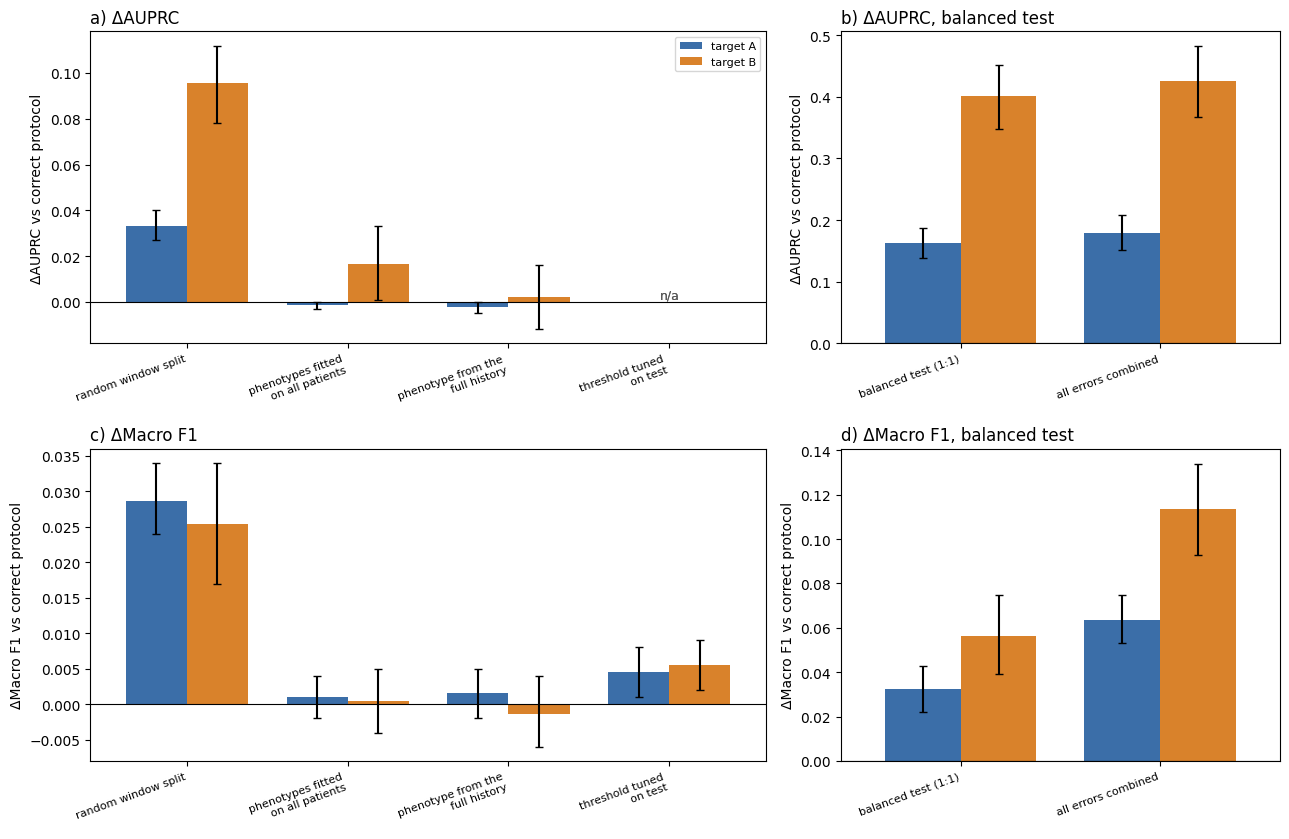

ΔAUPRC        Δmacro_F1       
target                                   A      B         A      B
variant                                                           
+ random window split                0.033  0.096     0.029  0.025
+ phenotypes fitted on all patients -0.001  0.016     0.001  0.000
+ phenotype from full history       -0.002  0.002     0.002 -0.001
+ threshold tuned on test              NaN    NaN     0.005  0.006
+ balanced test                      0.163  0.401     0.033  0.056
all errors combined                  0.179  0.425     0.063  0.113

In [6]:
EN = {'random window split': 'random window split', 'phenotypes fitted on all patients': 'phenotypes fitted\non all patients',
      'phenotype from full history': 'phenotype from the\nfull history',
      'threshold tuned on test': 'threshold tuned\non test', 'balanced test': 'balanced test (1:1)',
      'all errors combined': 'all errors combined'}
MODERATE = [E_SPLIT, E_PHENO_ALL, E_PHENO_FULL, E_THR]
LARGE = [E_BAL, 'all errors combined']
COLORS = {'A': '#3b6ea8', 'B': '#d9822b'}


def bars(ax, labels, metric):
    x = np.arange(len(labels))
    for i, t in enumerate(AUDIT_TARGETS):
        s_ = single_df[single_df.target == t].set_index('variant')
        for j, lab in enumerate(labels):
            key = lab if lab == 'all errors combined' else f'+ {lab}'
            if metric == 'AUPRC' and lab == E_THR:
                ax.text(j, 0, 'n/a', ha='center', va='bottom', fontsize=9, color='0.35')
                continue
            val = s_.loc[key, f'Δ{metric}']
            lo, hi = [float(v) for v in s_.loc[key, f'Δ{metric} 95% CI'].strip('[]').split(';')]
            ax.bar(j + (i - 0.5) * 0.38, val, 0.38, color=COLORS[t], label=f'target {t}' if j == 0 else None,
                   yerr=[[max(val - lo, 0)], [max(hi - val, 0)]], capsize=3)
    ax.axhline(0, color='k', lw=0.8)
    ax.set_xlim(-0.6, len(labels) - 0.4)
    ax.set_xticks(x)
    ax.set_xticklabels([EN[l] for l in labels], rotation=20, ha='right', fontsize=8)
    ax.set_ylabel({'AUPRC': 'ΔAUPRC', 'macro_F1': 'ΔMacro F1'}[metric] + ' vs correct protocol')


fig, axes = plt.subplots(2, 2, figsize=(13, 8.5), gridspec_kw={'width_ratios': [len(MODERATE), 2.6]})
bars(axes[0, 0], MODERATE, 'AUPRC'); axes[0, 0].set_title('a) ΔAUPRC', loc='left')
bars(axes[1, 0], MODERATE, 'macro_F1'); axes[1, 0].set_title('c) ΔMacro F1', loc='left')
bars(axes[0, 1], LARGE, 'AUPRC'); axes[0, 1].set_title('b) ΔAUPRC, balanced test', loc='left')
bars(axes[1, 1], LARGE, 'macro_F1'); axes[1, 1].set_title('d) ΔMacro F1, balanced test', loc='left')
axes[0, 0].legend(fontsize=8)
plt.tight_layout()
plt.savefig(os.path.join(OUT, 'leakage_single_en.png'), dpi=200, bbox_inches='tight')
plt.show()

summary = single_df.pivot_table(index='variant', columns='target', values=['ΔAUPRC', 'Δmacro_F1'], sort=False)
summary.loc['+ threshold tuned on test', 'ΔAUPRC'] = np.nan     # ranking does not change: n/a
summary.to_csv(os.path.join(OUT, 'leakage_summary.csv'))
display(summary.round(3))